*openmobisim tutorials* · [00 · overview](00_getting_started.ipynb) · ← [08 · Performance](08_performance.ipynb) · [documentation](https://openmobisim.github.io)

# 09 · Five minimal studies

What the simulator is for: studies. This notebook runs five of them, each small but honest, on one starter case —
Amsterdam's morning — and says for each what it leaves out. They are starting points to copy and extend, not results
about Amsterdam.

1. **Transit frequency**: a tram line run more often — the scenario sections 2 to 4 also compare with the base.
2. **Your own utility**: a choice model written in Python, with a term the built-in models cannot express.
3. **Accessibility**: the logsum (what the choice set is worth to each traveller) and travel-time matrices.
4. **Emissions**: CO₂ and NOₓ of the cars from their kilometres and speeds, with the European guidebook's factors.
5. **Disruptions**: a lane closed and a tram line stopped for an hour, travellers warned or not.

**Terms used here.**
- The **base run** is the case as it comes; a **scenario** changes one thing, and its effect is the difference from
  the base. Both use the same travellers and the same random draws (**common random numbers**), so a difference comes
  from the change, not from chance.
- A **starter case** is a network with what runs on it — a timetable, parkings, a demand and its traveller classes —
  prepared, checked and versioned (`examples.case`). Amsterdam's demand is a **synthetic morning** (06:30–09:30,
  about 496 000 people, five to each simulated traveller; the runs here take the departures from 07:30 to 08:30), made from open data and travel surveys to look like a
  morning, not to forecast one (notebook 02).
- A **traveller class** groups travellers who may use the same modes, own the same vehicles and weigh alternatives
  the same way (notebook 04). Amsterdam's are the package's example classes (`examples.traveller_classes()`): four,
  by what people own — a car and a bike, a bike only, a car only, neither — each free to use every mode its vehicles
  allow, all weighing alike, with illustrative constants; and three for what enters from outside the city and does not
  choose here (cars, transit riders, goods vehicles: notebook 02).

The case's morning simulates one traveller for every five people (its `weight`): the **fast run**, close to the
complete one for most purposes and a few times faster. Every study below uses it; **the last section runs the
complete morning once**, one simulated traveller per person, to compare.

**Start small: Delft.** Every study here also runs on Delft, the smallest starter city, in seconds a run: name
`"delft"` instead of `"amsterdam"` in the next cell and run the notebook again. Its base, for a first look:

**Download** {download}`this notebook <../_static/notebooks/09_applications.ipynb>` or {download}`all ten <../_static/notebooks/openmobisim_notebooks.zip>` (a zip), without their outputs. The Installation section below installs openmobisim; its last command, `openmobisim notebooks`, copies the same ten into a folder and opens the first in JupyterLab.

---

## Installation

> Skip this if `import openmobisim` already works in this notebook. **One install is all there is:**
> `pip install "openmobisim[all]"` brings the simulator and everything the ten tutorials use (JupyterLab,
> matplotlib for the figures, pandas, polars and pyarrow for the tables); nothing is installed later. Find the case
> that matches yours and copy its commands, in order. Each needs Python 3.11 or newer.
>
> **A new conda environment** (any system; openmobisim is on PyPI, so pip installs it into the environment):
>
> ```bash
> conda create -y -n openmobisim python=3.12
> conda activate openmobisim
> pip install "openmobisim[all]"
> openmobisim notebooks
> ```
>
> **A new venv on macOS or Linux** (in a terminal):
>
> ```bash
> python3 -m venv openmobisim
> source openmobisim/bin/activate
> pip install "openmobisim[all]"
> openmobisim notebooks
> ```
>
> **A new venv on Windows** (in the Command Prompt):
>
> ```bat
> py -m venv openmobisim
> openmobisim\Scripts\activate
> pip install "openmobisim[all]"
> openmobisim notebooks
> ```
>
> The last line copies these ten notebooks into `./openmobisim-notebooks` and opens them in JupyterLab. In VS Code or
> PyCharm, open a notebook and choose the `openmobisim` environment's Python as its kernel instead.
>
> **Into the environment this notebook already runs in**: paste this into a new code cell, run it, then restart the
> kernel.
>
> ```python
> %pip install "openmobisim[all]"
> ```

---

In [1]:
import collections

import numpy as np
import pandas as pd

import openmobisim as ms
from openmobisim import choice, viz

# Delft's whole morning: every departure (06:30-09:30), run on to 10:30 so the late ones arrive.
delft = ms.examples.case("delft").scenario("base", departures="all", window=("06:30", "10:30")).run(
    "delft-base", output_dir="runs/delft-base", quiet=True
)
print(f"Delft's morning: {delft.completion['total_trips']} travellers simulated, {delft.timings()['seconds'][-1]:.1f} s")

Delft's morning: 113709 travellers simulated, 17.7 s


/var/folders/q0/vjghqqvj4dvcq_z2rjmvd0jmw3f5y2/T/ipykernel_5161/3873984929.py:10: NoAlternativeWarning: 3 trips (3 people, 0.0% of run 'delft-base') had no alternative — no mode they may use reached their destination within the limits — and were not simulated. By class (stated mode): 2 'no_vehicle' (choosing), 1 'from_outside_transit' (transit). Why, by mode offered (trips): walk: walk_too_long 2; transit: no_stop_in_reach 3. Most between (latitude, longitude, about 1 km): 1 people from (51.98, 4.38) to (51.98, 4.40); 1 people from (51.98, 4.40) to (51.98, 4.37); 1 people from (52.01, 4.36) to (51.97, 4.39). To change: walk_too_long: mode_options['walk_max_s'] or the class's walk_max_s; no_stop_in_reach: transit_options['access_walk_max_s'] or the class's access_walk_max_s. Run.report_no_alternative() lists every trip with its reasons.
  delft = ms.examples.case("delft").scenario("base", departures="all", window=("06:30", "10:30")).run(


In [2]:
case = ms.examples.case("amsterdam")  # found in the cache, or downloaded once and checked
net = case.network()
transit = case.transit(net)
parkings = case.parkings()
classes = case.classes()  # the example classes, and those of what enters from outside (above)
trips = case.demand()  # the fast run: five people a simulated traveller
print(case.info["title"], net, transit, parkings, f"{len(trips)} trips simulated", sep="\n")

Amsterdam
Network(115389 nodes, 252184 links, with street geometry)
Transit(2026-10-09: 7221 runs, 1868 stops, 171 lines)
Parkings(18 car, 1134 bike)
57381 trips simulated


Every run below goes through one function, so each scenario differs from the base only in what it is given. Each run
records **link bins** (`link_bin_s=900`): per road, bike and walk link and per 15 minutes, the traffic that left the
link and the time it took — what sections 4 and 5 read.

In [3]:
MODES = {
    "walk": "walk", "bike": "bike", "car": "car", "transit": "transit",
    "car_transit": "park-and-ride", "bike_transit": "bike-and-ride", None: "no alternative",
}  # fmt: skip
runs = {}


def simulate(name, network=net, timetable=transit, traveller_classes=classes, **options):
    settings = case.info["scenarios"]["base"] | options  # the case's: link bins, shared searches, a good gap
    run = ms.Scenario.from_parts(
        network, trips, classes=traveller_classes, transit=timetable, parkings=parkings, **settings,
    ).run(name, output_dir=f"runs/{name}", quiet=True)  # fmt: skip
    runs[name] = run
    return run


def row(run):
    """One scenario's line in the tables: mode shares by people, the mean trip and the run time."""
    modes = run.trip_modes()
    people = collections.Counter()
    for mode, weight in zip(modes["mode"], modes["weight"]):
        people[MODES[mode]] += weight
    total = sum(people.values())
    return {f"{label} (%)": 100 * people[label] / total for label in MODES.values()} | {
        "mean trip (min)": run.mean_travel_time_s / 60,
        "run time (s)": run.timings()["seconds"][-1],
    }


def table(*names):
    return pd.DataFrame([row(runs[n]) for n in names], index=pd.Index(names, name="run")).round(2)


base = simulate("base")
table("base")

/var/folders/q0/vjghqqvj4dvcq_z2rjmvd0jmw3f5y2/T/ipykernel_5161/2287325879.py:12: NoAlternativeWarning: 311 trips (1,555 people, 0.5% of run 'base') had no alternative — no mode they may use reached their destination within the limits — and were not simulated. By class (stated mode): 277 'no_vehicle' (choosing), 33 'from_outside_transit' (transit), 1 'car_and_bike' (choosing). Why, by mode offered (trips): car: no_road_route 1; bike: ride_too_long 1; walk: walk_too_long 278; transit: no_stop_in_reach 206, no_transit_journey 105; car_transit: too_short 1; bike_transit: too_short 1. Most between (latitude, longitude, about 1 km): 25 people from (52.39, 4.84) to (52.41, 4.85); 15 people from (52.38, 4.90) to (52.40, 4.87); 15 people from (52.40, 4.91) to (52.41, 4.85); 15 people from (52.41, 4.81) to (52.42, 4.82); 10 people from (52.35, 4.81) to (52.40, 4.87). To change: walk_too_long: mode_options['walk_max_s'] or the class's walk_max_s; ride_too_long: mode_options['bike_max_s'] or the 

,walk (%),bike (%),car (%),transit (%),park-and-ride (%),bike-and-ride (%),no alternative (%),mean trip (min),run time (s)
run,,,,,,,,,
base,2.13,33.77,35.31,27.81,0.13,0.37,0.48,25.44,34.71


## 1 · Transit frequency

`transit_edit` returns a changed copy of the timetable: a line cancelled, or run at another **headway** (the time
between two departures) within a window. The study: the tram line with the most boardings in the base run, every
4 minutes from 07:00 to 09:00 in each direction.

In [4]:
calls = base.transit_calls()
boardings = collections.Counter()
for line, kind, b in zip(calls["line"], calls["kind"], calls["boardings"]):
    if kind == "tram":
        boardings[line] += b
line, _ = boardings.most_common(1)[0]
lines = transit.lines()
route = next(r for r, n, k in zip(lines["route_id"], lines["name"], lines["kind"]) if n == line and k == "tram")
frequent = ms.transit_edit(transit, headway={route: (240, 7 * 3600, 9 * 3600)})


def tram(run, timetable):
    c = run.transit_calls()
    t = timetable.lines()
    i = t["route_id"].index(route)
    on_line = [b for ln, k, b in zip(c["line"], c["kind"], c["boardings"]) if ln == line and k == "tram"]
    transit_mode = run.completion_by_mode["transit"]
    return {
        "runs of the line in the day": t["runs"][i],
        "boardings on the line": sum(on_line),
        "boardings, all transit": run.transit_summary["boardings"],
        "mean transit trip (min)": transit_mode["total_travel_time_s"] / transit_mode["completed_people"] / 60,
    }


more = simulate("tram every 4 min", timetable=frequent)
print(f"tram line {line} (route {route})")
pd.DataFrame(
    [tram(base, transit), tram(more, frequent)], index=pd.Index(["base", "tram every 4 min"], name="run")
).round(1)

tram line 1 (route 152323)


/var/folders/q0/vjghqqvj4dvcq_z2rjmvd0jmw3f5y2/T/ipykernel_5161/2287325879.py:12: NoAlternativeWarning: 310 trips (1,550 people, 0.5% of run 'tram every 4 min') had no alternative — no mode they may use reached their destination within the limits — and were not simulated. By class (stated mode): 276 'no_vehicle' (choosing), 33 'from_outside_transit' (transit), 1 'car_and_bike' (choosing). Why, by mode offered (trips): car: no_road_route 1; bike: ride_too_long 1; walk: walk_too_long 277; transit: no_stop_in_reach 206, no_transit_journey 104; car_transit: too_short 1; bike_transit: too_short 1. Most between (latitude, longitude, about 1 km): 25 people from (52.39, 4.84) to (52.41, 4.85); 15 people from (52.38, 4.90) to (52.40, 4.87); 15 people from (52.40, 4.91) to (52.41, 4.85); 15 people from (52.41, 4.81) to (52.42, 4.82); 10 people from (52.35, 4.81) to (52.40, 4.87). To change: walk_too_long: mode_options['walk_max_s'] or the class's walk_max_s; ride_too_long: mode_options['bike_max

,runs of the line in the day,boardings on the line,"boardings, all transit",mean transit trip (min)
run,,,,
base,100,3650.0,131905.0,39.9
tram every 4 min,152,5495.0,132595.0,39.6


Line 1 runs 152 times instead of 100 and its boardings rise from 3 650 to 5 495, while all transit boardings hardly
move (131 905, then 132 595): most of its new riders came from other lines, and the mean transit trip shortens from
39.9 to 39.6 minutes. Mode shares hardly move — those who own a car or a bike seldom take transit in this
morning, which is mostly slower for them door to door:

In [5]:
table("base", "tram every 4 min")

,walk (%),bike (%),car (%),transit (%),park-and-ride (%),bike-and-ride (%),no alternative (%),mean trip (min),run time (s)
run,,,,,,,,,
base,2.13,33.77,35.31,27.81,0.13,0.37,0.48,25.44,34.71
tram every 4 min,2.12,33.70,35.37,27.83,0.12,0.38,0.48,25.41,35.05


**What this leaves out.** No crowding and no vehicle capacity: a more frequent line shortens waits and transfers, and
nothing else. Trams run by the timetable; buses would also ride the roads among the cars.

## 2 · Your own utility

In section 1 the more frequent tram drew riders from other lines but hardly changed who takes transit: the built-in
model weighs a walk to the stop by its minutes, each alike. Many people weigh a long walk more than its minutes —
the tenth minute on foot is not the first.

A choice model is any Python object with a `choose(batch)` method: the batch holds every alternative's attributes as
NumPy arrays (`time_min`, `walk_min`, `wait_min`, `transfers`, `bike_mixed_km`, the mode dummies `mode_bike` …), the
traveller's class, and the random draws the built-in models use. The model below is **the built-in logit rewritten in
Python** — the same coefficients, each class's own from the class table — **plus one term the built-in linear models
cannot express**: for the travellers who own no vehicle (who walk to every stop), every minute on foot beyond the
first ten costs twice its weight (a threshold, so not linear). A *logsum* method
(section 3) and the probabilities (for the convergence measure) come with it.

In [6]:
DEFAULTS = {"time_min": -0.2, "ln_path_size": 1.0, "transfers": -1.0, "wait_min": -0.09, "walk_min": -0.13}


class LongWalkAversion:
    name = "long_walk_aversion"

    def __init__(self, classes, free_min=10.0, factor=2.0, who="no_vehicle"):
        self.betas = {
            name: DEFAULTS | {k[len("beta_"):]: v for k, v in c.get("betas", {}).items()}
            for name, c in classes.items()
        }
        self.free_min, self.factor, self.who = free_min, factor, who
        # In the run's fingerprint: change it whenever the model's behaviour changes.
        self.descriptor = f"long_walk_aversion;v1;x{factor} beyond {free_min} min;{who}"

    def utility(self, batch):
        cls = batch.user_class[batch.situation_of]  # each alternative's traveller class
        u = np.zeros(len(cls))
        for k, name in enumerate(batch.class_names):
            mine = cls == k
            for attribute, beta in self.betas.get(name, DEFAULTS).items():
                u[mine] += beta * batch.attributes[attribute][mine]
        if self.who in batch.class_names:
            walker = cls == batch.class_names.index(self.who)
            beyond = np.maximum(batch.attributes["walk_min"] - self.free_min, 0.0)
            u[walker] += (self.factor - 1.0) * self.betas[self.who]["walk_min"] * beyond[walker]
        return u

    def choose(self, batch):
        return choice.sample_random_utility(batch, self.utility(batch))

    def probabilities(self, batch):
        return choice.segment_softmax(self.utility(batch), batch.offsets)

    def logsum(self, batch):
        u = self.utility(batch)
        starts = np.asarray(batch.offsets[:-1], dtype=np.int64)
        top = np.maximum.reduceat(u, starts)
        return top + np.log(np.add.reduceat(np.exp(u - top[batch.situation_of]), starts))


# The model holds the classes' coefficients itself, so the runs get the classes without them.
modes_only = {name: {k: v for k, v in c.items() if k != "betas"} for name, c in classes.items()}
model = LongWalkAversion(classes)
averse = simulate("own model", choice_model=model, traveller_classes=modes_only)
averse_frequent = simulate(
    "own model, tram every 4 min", timetable=frequent, choice_model=model, traveller_classes=modes_only
)
table("base", "tram every 4 min", "own model", "own model, tram every 4 min")

/var/folders/q0/vjghqqvj4dvcq_z2rjmvd0jmw3f5y2/T/ipykernel_5161/2287325879.py:12: NoAlternativeWarning: 302 trips (1,510 people, 0.5% of run 'own model') had no alternative — no mode they may use reached their destination within the limits — and were not simulated. By class (stated mode): 267 'no_vehicle' (choosing), 33 'from_outside_transit' (transit), 1 'bike_only' (choosing), 1 'car_and_bike' (choosing). Why, by mode offered (trips): car: no_road_route 1; bike: ride_too_long 2; walk: walk_too_long 269; transit: no_stop_in_reach 206, no_transit_journey 96; car_transit: too_short 1; bike_transit: no_transit_journey 1, too_short 1. Most between (latitude, longitude, about 1 km): 25 people from (52.39, 4.84) to (52.41, 4.85); 15 people from (52.38, 4.90) to (52.40, 4.87); 15 people from (52.40, 4.91) to (52.41, 4.85); 10 people from (52.35, 4.81) to (52.40, 4.87); 10 people from (52.35, 4.85) to (52.41, 4.82). To change: walk_too_long: mode_options['walk_max_s'] or the class's walk_max_

/var/folders/q0/vjghqqvj4dvcq_z2rjmvd0jmw3f5y2/T/ipykernel_5161/2287325879.py:12: NoAlternativeWarning: 298 trips (1,490 people, 0.5% of run 'own model, tram every 4 min') had no alternative — no mode they may use reached their destination within the limits — and were not simulated. By class (stated mode): 263 'no_vehicle' (choosing), 33 'from_outside_transit' (transit), 1 'bike_only' (choosing), 1 'car_and_bike' (choosing). Why, by mode offered (trips): car: no_road_route 1; bike: ride_too_long 2; walk: walk_too_long 265; transit: no_stop_in_reach 206, no_transit_journey 92; car_transit: too_short 1; bike_transit: no_transit_journey 1, too_short 1. Most between (latitude, longitude, about 1 km): 25 people from (52.39, 4.84) to (52.41, 4.85); 15 people from (52.38, 4.90) to (52.40, 4.87); 15 people from (52.40, 4.91) to (52.41, 4.85); 10 people from (52.35, 4.81) to (52.40, 4.87); 10 people from (52.35, 4.85) to (52.41, 4.82). To change: walk_too_long: mode_options['walk_max_s'] or the

,walk (%),bike (%),car (%),transit (%),park-and-ride (%),bike-and-ride (%),no alternative (%),mean trip (min),run time (s)
run,,,,,,,,,
base,2.13,33.77,35.31,27.81,0.13,0.37,0.48,25.44,34.71
tram every 4 min,2.12,33.70,35.37,27.83,0.12,0.38,0.48,25.41,35.05
own model,1.84,33.10,36.01,28.04,0.10,0.43,0.47,25.61,32.41
"own model, tram every 4 min",1.82,33.14,35.96,28.08,0.11,0.43,0.46,25.47,32.73


The modes chosen by the travellers who own no vehicle, in the four runs (other classes face the same utilities as in
the base run):

In [7]:
def shares_by_class(run):
    ch = run.itinerary_choices()
    counts = collections.defaultdict(collections.Counter)
    for cls, mode, chose in zip(ch["user_class"], ch["mode"], ch["mode_choice"]):
        if chose:
            counts[cls][MODES[mode]] += 1
    t = pd.DataFrame(counts).T.fillna(0)
    return (100 * t.div(t.sum(axis=1), axis=0)).round(1)


four = ["base", "tram every 4 min", "own model", "own model, tram every 4 min"]
pd.DataFrame({n: shares_by_class(runs[n]).loc["no_vehicle"] for n in four}).T.rename_axis("run")

,bike,bike-and-ride,car,no alternative,park-and-ride,transit,walk
run,,,,,,,
base,0.0,0.0,0.0,2.2,0.0,89.1,8.8
tram every 4 min,0.0,0.0,0.0,2.2,0.0,89.1,8.7
own model,0.0,0.0,0.0,2.1,0.0,90.3,7.6
"own model, tram every 4 min",0.0,0.0,0.0,2.1,0.0,90.4,7.5


With the built-in model this class's transit share is 89.1 % (89.2 % with the frequent tram): travellers who own no
vehicle already take transit for nearly every trip they do not walk (2.1 % have no alternative at all). With the
aversion to long walks, walking falls from 8.8 % to 7.6 % and transit rises to 90.3 % (90.4 % with the tram), again
hardly moved by the tram. How much a change matters depends on the tastes the model carries — which is what data on
route and mode choice is for.

**What this leaves out.** The coefficients are illustrative. A model in Python is called once per batch of up to
32 768 choices, so vectorised NumPy costs little; a loop over travellers would not. This model leaves money out: every
alternative carries what it costs (`cost_eur` and its parts: running costs, tolls, parking fees, fares, at the prices
of `price_options`, all 0 by default: having a car or a pass is what a class has), and a model weighs it like any
attribute.

## 3 · Accessibility

Geurs and van Wee (2004) describe accessibility by four components: land use (where the opportunities are), transport
(how long and how costly it is to reach them), time (when) and the individual (who travels, with which means). Two
common measures, both available after a run:

- The **logsum**: the expected utility of the best alternative in a traveller's choice set,
  `ln Σ exp(utility)`. It grows when an alternative improves or is added, and divided by the time coefficient's size
  (0.2 per minute here) it reads in minutes: how many minutes of travel time the change is worth. It is
  **utility-based** and individual: it reflects each class's modes and tastes.
- **Cumulative opportunities**: how many opportunities are reached within a time limit, from a **skim** (a matrix of
  travel times between zones, by mode and departure time). It is **location-based**: one number per zone and mode.

In [8]:
def logsum_min(run):
    ch = run.itinerary_choices()
    t = pd.DataFrame({"class": ch["user_class"], "logsum": ch["logsum"], "chose": ch["mode_choice"]})
    return t[t["chose"]].groupby("class")["logsum"].mean() / 0.2


access = pd.DataFrame({"base (min)": logsum_min(base), "tram every 4 min (min)": logsum_min(more)})
access["change (min)"] = access["tram every 4 min (min)"] - access["base (min)"]
access.round(3)

,base (min),tram every 4 min (min),change (min)
class,,,
bike_only,-17.530,-17.532,-0.002
car_and_bike,-13.245,-13.248,-0.003
car_only,-20.441,-20.445,-0.003
no_vehicle,-59.964,-59.624,0.340


The levels are not meaningful on their own (a logsum is defined up to a constant); the change is. The frequent tram is
worth 0.34 minutes per trip to those who own no vehicle; for those who own a vehicle the change is a few thousandths
of a minute (−0.002 with a bike only, −0.003 with both, −0.003 with a car only): they seldom take the tram,
and what moves their logsum is the traffic, which shifts a little from run to run.

The same by origin-destination pair, the zones of the demand: `Run.logsum_od` averages the trips' logsums over each
pair (weighted by the people they stand for), so two designs compare pair by pair. The pairs that gain most:

In [9]:
pairs = [pd.DataFrame(r.logsum_od(trips, case.zones())).set_index(["origin", "destination"]) for r in (base, more)]
gain = pd.DataFrame({"trips": pairs[0]["trips"], "change (min)": (pairs[1]["logsum"] - pairs[0]["logsum"]) / 0.2})
gain[gain["trips"] >= 20].sort_values("change (min)", ascending=False).head(5).round(3)

,,trips,change (min)
origin,destination,,
r03c09,r03c05,20.0,0.569
r11c10,r11c11,20.0,0.567
st000,r15c07,21.0,0.489
r03c05,r03c05,20.0,0.157
r10c15,r11c15,22.0,0.080


Now the skims, from the base run, leaving at 08:00: car on the loaded link times (congestion included), bike and walk
on their layers, transit on the timetable with its walks. As **opportunities**, the morning's arrivals per zone stand
in for jobs and schools (the demand is synthetic, so this is a placeholder for real land-use data).

In [10]:
zones = case.zones()
arrivals = collections.Counter()
for r in ms.demand_read_od(case.path(case.info["demand"]["od"])):
    arrivals[r["destination_zone"]] += float(r["trips"])
opportunities = np.array([arrivals[z] for z in zones])

reach = {}
for mode in ("walk", "bike", "transit", "car"):
    minutes = base.skim(mode, zones, departure_s=8 * 3600, max_s=2 * 3600) / 60
    within = np.nan_to_num(minutes, nan=np.inf) <= 30
    reach[mode] = 100 * (within * opportunities).sum(axis=1) / opportunities.sum()
pd.DataFrame(
    {
        "mean (%)": [reach[m].mean() for m in reach],
        "lowest zone (%)": [reach[m].min() for m in reach],
        "highest zone (%)": [reach[m].max() for m in reach],
    },
    index=pd.Index(list(reach), name="mode, leaving at 08:00"),
).round(1)

,mean (%),lowest zone (%),highest zone (%)
"mode, leaving at 08:00",,,
walk,2.7,0.0,8.7
bike,27.5,1.0,57.8
transit,7.5,0.0,46.0
car,85.5,0.0,99.5


The table gives, over the case's 354 zones (its 1-km grid, its stations and gateways), the share of all the morning's
destinations reachable within 30 minutes: from the average zone, 27.5 % by bike, 7.6 % by transit, 2.7 % on foot and
86.5 % by car (see below what the car skim leaves out). A skim runs one search per origin, so the four matrices take
seconds; skims by time of day, or before and after a change, are as cheap.

**What this leaves out.** Opportunities here are a stand-in; the logsum covers the trips simulated, not every zone pair;
skims ignore the classes' own limits and car ownership (the individual component is in the logsum, not the skim); a
car skim runs from the nearest drivable point to the nearest, with no walk to the car and no parking, so it
flatters the car.

## 4 · Emissions

Road traffic's exhaust emissions are estimated by multiplying **vehicle-kilometres** (one vehicle driving one
kilometre) by an **emission factor** (grams per kilometre) that depends on the vehicle and on how it is driven.
The EMEP/EEA air pollutant emission inventory guidebook (2023, chapter 1.A.3.b.i-iv, its Appendix 4; the factors of
the COPERT model) gives the factors as functions of the **average speed** `v` in km/h:

`EF(v) = (α v² + β v + γ + δ / v) / (ε v² + ζ v + η) · (1 − reduction)`

for energy use (MJ/km, from which CO₂ follows by the fuel's carbon) and for each pollutant. Two levels:
- **E0, distance only**: every kilometre at one typical urban speed (30 km/h here);
- **E2, speed per link and time**: each link's mean speed in each 15 minutes (its length over its mean traversal time),
  so congestion raises the factor where traffic is slow.

The fleet: medium passenger cars of the newest standard (Euro 6 d/e), 60 % petrol, 25 % diesel and 15 % battery
electric — **illustrative shares**: use the study area's registrations. CO₂ is tank-to-wheel (69.3 g/MJ for petrol,
74.1 g/MJ for diesel, the IPCC 2006 defaults); an electric car emits none at the exhaust.

In [11]:
# Appendix 4, sheet HOT_EMISSIONS_PARAMETERS: Passenger Cars, Medium, Euro 6 d/e (petrol GDI+GPF, diesel DPF+SCR).
FACTORS = pd.DataFrame(
    [
        ("petrol", "EC", 5, 130, 0.000131723006778538, 0.0054859592952839, 2.6191950512566,
         1.72774612390592e-09, -8.50415012699799e-05, 0.023584384067406, 0.344297577833879, 0.23196729231897276),
        ("petrol", "NOx", 5, 130, -0.000314540672240406, 0.103056777252331, 0.239056575951972,
         -0.3392791490405, 0.0345358283618128, 1.98601274556741, 1.26376326022528, 0.0),
        ("diesel", "EC", 10, 130, -0.00129911063069031, 0.221624989207713, 16.4359146120605,
         5.66298857668099e-09, -0.00184467928314896, 0.292347275962134, 2.37716402519569, 0.08086995278390967),
        ("diesel", "NOx", 10, 130, 6.67136e-05, -0.011381467, 0.945951727, 1.923608149, -5.15046e-05, 0.004264272,
         1.0, 0.92),
    ],
    columns=["fuel", "quantity", "v_min", "v_max", "alpha", "beta", "gamma", "delta", "epsilon", "zeta", "eta",
             "reduction"],
)  # fmt: skip
FLEET = {"petrol": 0.60, "diesel": 0.25, "electric": 0.15}
CO2_G_PER_MJ = {"petrol": 69.3, "diesel": 74.1}


def factor(fuel, quantity, v):
    f = FACTORS[(FACTORS["fuel"] == fuel) & (FACTORS["quantity"] == quantity)].iloc[0]
    v = np.clip(v, f["v_min"], f["v_max"])
    top = f["alpha"] * v**2 + f["beta"] * v + f["gamma"] + f["delta"] / v
    return top / (f["epsilon"] * v**2 + f["zeta"] * v + f["eta"]) * (1 - f["reduction"])


def per_km(v):
    """The fleet's mean CO₂ and NOₓ in g/km at speed v (km/h)."""
    co2 = sum(FLEET[f] * factor(f, "EC", v) * CO2_G_PER_MJ[f] for f in ("petrol", "diesel"))
    nox = sum(FLEET[f] * factor(f, "NOx", v) for f in ("petrol", "diesel"))
    return co2, nox


speeds = np.array([10.0, 20.0, 30.0, 50.0, 80.0, 100.0])
co2, nox = per_km(speeds)
pd.DataFrame(
    {"CO₂ (g/km)": co2, "NOₓ (g/km)": nox}, index=pd.Index(speeds, name="average speed (km/h)")
).round(3)

,CO₂ (g/km),NOₓ (g/km)
average speed (km/h),,
10.0,211.766,0.049
20.0,159.880,0.039
30.0,134.365,0.033
50.0,111.881,0.025
80.0,105.390,0.020
100.0,110.442,0.019


In [12]:
road_km = net.link_length_m() / 1000


def emissions(run):
    bins = run.link_bins("road")
    links, pcu, pcu_s = bins.links(), bins.pcu(), bins.pcu_seconds()
    vkm = pcu * road_km[links]
    speed = road_km[links] / (pcu_s / pcu / 3600)
    co2_0, nox_0 = per_km(np.full(len(vkm), 30.0))
    co2_2, nox_2 = per_km(speed)
    return {
        "vehicle-km": vkm.sum(),
        "mean speed (km/h)": vkm.sum() / (pcu_s.sum() / 3600),
        "CO₂, E0 (t)": (vkm * co2_0).sum() / 1e6,
        "CO₂, E2 (t)": (vkm * co2_2).sum() / 1e6,
        "NOₓ, E0 (kg)": (vkm * nox_0).sum() / 1e3,
        "NOₓ, E2 (kg)": (vkm * nox_2).sum() / 1e3,
    }


pd.DataFrame([emissions(runs[n]) for n in ("base", "tram every 4 min")],
             index=pd.Index(["base", "tram every 4 min"], name="run")).round(1)  # fmt: skip

,vehicle-km,mean speed (km/h),"CO₂, E0 (t)","CO₂, E2 (t)","NOₓ, E0 (kg)","NOₓ, E2 (kg)"
run,,,,,,
base,1342575.4,38.2,180.4,157.9,44.7,31.7
tram every 4 min,1345531.1,38.1,180.8,158.4,44.8,31.8


E2 gives less than E0 here (157.9 against 180.4 tonnes of CO₂) because the cars' mean speed, 38.2 km/h, is above the
30 km/h E0 assumes, and the factors fall with speed up to about 80 km/h (the table of factors above). The frequent
tram takes no one out of a car (car kilometres change by +0.22 %, within the variation of the others' routes): those
who own one seldom take it.

**What this leaves out.** Hot exhaust only: no cold starts (the guidebook's own correction for the first kilometres),
no evaporation, tyre or brake wear. Buses on the roads are counted with the cars, in passenger-car units, not with
their own factors. An average speed misses stop-and-go driving within a link (the guidebook's higher tiers, and
emission models fed with speed profiles, are later steps). The fleet shares are illustrative.

**References.**
- European Environment Agency (2023). *EMEP/EEA air pollutant emission inventory guidebook 2023*, EEA Report
  06/2023. Part B, chapter 1.A.3.b.i-iv *Road transport*, and its Appendix 4 (the emission factors: sheet
  `HOT_EMISSIONS_PARAMETERS`, used above). https://www.eea.europa.eu/publications/emep-eea-guidebook-2023
- Ntziachristos, L., Gkatzoflias, D., Kouridis, C. and Samaras, Z. (2009). COPERT: a European road transport
  emission inventory model. In *Information Technologies in Environmental Engineering*, Springer, 491–504.
  https://doi.org/10.1007/978-3-540-88351-7_37
- IPCC (2006). *2006 IPCC Guidelines for National Greenhouse Gas Inventories*, Volume 2 *Energy*, chapter 3
  *Mobile combustion*, Table 3.2.1 (road transport's default CO₂ factors: 69 300 kg/TJ for motor gasoline,
  74 100 kg/TJ for gas/diesel oil). Eggleston, H.S., Buendia, L., Miwa, K., Ngara, T. and Tanabe, K. (eds), IGES,
  Japan. https://www.ipcc-nggip.iges.or.jp/public/2006gl/

## 5 · Disruptions

A **disruption** happens at a time of day: on a road, a share of a link's capacity is lost for a while (0 closes it);
on a line, the runs leaving their first stop within a window are late or cancelled. Travellers may **not know** of it
in advance (the default: an accident, a breakdown): the run reaches its equilibrium without it, then loads the morning
once more with it, every choice kept — only passengers whose tram never comes plan again at the stop. This is the
**zero-adaptation** impact. Or they **know** (works announced, a strike): every iteration has it, and routes and modes
adapt.

The study, from 07:30 to 08:30: the busiest two-lane road link of that hour in the base run closed (an accident), and
the tram line of section 1 not running (a breakdown).

In [13]:
bins = base.link_bins("road")
start = bins.bins() * 900  # bin k starts k × 15 minutes after midnight
hour = (start >= 7.5 * 3600) & (start < 8.5 * 3600)
volume = collections.Counter()
for link, pcu in zip(bins.links()[hour], bins.pcu()[hour]):
    volume[int(link)] += pcu
closed = next(k for k, _ in volume.most_common() if net.link_lanes()[k] == 2)
kind = ms.LINK_CLASSES[net.link_class()[closed]]
print(f"road link {net.link_ids()[closed]} ({kind}): {volume[closed]:.0f} PCU from 07:30 to 08:30 in the base run")
events = [
    {"links": [closed], "capacity_factor": 0.0, "from_s": 7.5 * 3600, "to_s": 8.5 * 3600},
    {"line": route, "cancel": True, "from_s": 7.5 * 3600, "to_s": 8.5 * 3600},
]
unknown = simulate("disruptions, unknown", disruptions=events)
known = simulate("disruptions, known", disruptions=events, disruptions_known=True)


def impact(run):
    by_mode = run.completion_by_mode
    b = run.link_bins("road")
    on = (b.links() == closed) & (b.bins() * 900 >= 7.5 * 3600) & (b.bins() * 900 < 9 * 3600)
    return {
        f"mean {m} trip (min)": by_mode[m]["total_travel_time_s"] / by_mode[m]["completed_people"] / 60
        for m in ("car", "transit")
    } | {
        "car travel, total (h)": by_mode["car"]["total_travel_time_s"] / 3600,
        "PCU leaving the closed link, 07:30–09:00": b.pcu()[on].sum(),
    }


names = ["base", "disruptions, unknown", "disruptions, known"]
pd.DataFrame([impact(runs[n]) for n in names], index=pd.Index(names, name="run")).round(2)

road link 1074249831:00060678 (motorway): 3400 PCU from 07:30 to 08:30 in the base run


/var/folders/q0/vjghqqvj4dvcq_z2rjmvd0jmw3f5y2/T/ipykernel_5161/2287325879.py:12: NoAlternativeWarning: 311 trips (1,555 people, 0.5% of run 'disruptions, unknown') had no alternative — no mode they may use reached their destination within the limits — and were not simulated. By class (stated mode): 277 'no_vehicle' (choosing), 33 'from_outside_transit' (transit), 1 'car_and_bike' (choosing). Why, by mode offered (trips): car: no_road_route 1; bike: ride_too_long 1; walk: walk_too_long 278; transit: no_stop_in_reach 206, no_transit_journey 105; car_transit: too_short 1; bike_transit: too_short 1. Most between (latitude, longitude, about 1 km): 25 people from (52.39, 4.84) to (52.41, 4.85); 15 people from (52.38, 4.90) to (52.40, 4.87); 15 people from (52.40, 4.91) to (52.41, 4.85); 15 people from (52.41, 4.81) to (52.42, 4.82); 10 people from (52.35, 4.81) to (52.40, 4.87). To change: walk_too_long: mode_options['walk_max_s'] or the class's walk_max_s; ride_too_long: mode_options['bike

/var/folders/q0/vjghqqvj4dvcq_z2rjmvd0jmw3f5y2/T/ipykernel_5161/2287325879.py:12: NoAlternativeWarning: 284 trips (1,420 people, 0.5% of run 'disruptions, known') had no alternative — no mode they may use reached their destination within the limits — and were not simulated. By class (stated mode): 250 'no_vehicle' (choosing), 33 'from_outside_transit' (transit), 1 'car_and_bike' (choosing). Why, by mode offered (trips): car: no_road_route 1; bike: ride_too_long 1; walk: walk_too_long 251; transit: no_stop_in_reach 206, no_transit_journey 78; car_transit: too_short 1; bike_transit: too_short 1. Most between (latitude, longitude, about 1 km): 25 people from (52.39, 4.84) to (52.41, 4.85); 15 people from (52.38, 4.90) to (52.40, 4.87); 15 people from (52.40, 4.91) to (52.41, 4.85); 10 people from (52.35, 4.81) to (52.40, 4.87); 10 people from (52.35, 4.85) to (52.41, 4.82). To change: walk_too_long: mode_options['walk_max_s'] or the class's walk_max_s; ride_too_long: mode_options['bike_ma

,mean car trip (min),mean transit trip (min),"car travel, total (h)","PCU leaving the closed link, 07:30–09:00"
run,,,,
base,20.10,39.85,33930.95,4505.0
"disruptions, unknown",21.22,41.44,35832.19,1875.0
"disruptions, known",21.23,40.19,35669.51,1490.0


Unwarned, drivers keep their routes and wait at the closed road until it reopens: the morning's car travel rises from
33 931 to 35 832 hours (the mean car trip from 20.1 to 21.2 minutes). Warned, those who would have met the closure take
other roads (and a few the bike: the summary below), and car travel rises a little less, to 35 670 hours (the mean car
trip still about 21.2 minutes): each driver who detours saves time, but the detours load roads others use, so warning
them recovers only an eighth of the loss. The road passes nothing from 07:30 to 08:30 and then what its capacity lets
through, 1 875 PCU by 09:00 unwarned and 1 490 warned (fewer drivers are still bound for it), against 4 505 in the
base. The mean transit trip rises from 39.9 to 41.4 minutes when the tram stops without warning, and to 40.2 when
riders know.

**What this leaves out.** Unwarned drivers do not turn back: at the default loading (a point queue) they wait at the
closed road until it opens, so the unknown case is an upper bound on the delay; en-route re-routing exists at the
loadings with spillback (`flow_level=3` and `4`). Nobody learns of the disruption part-way through the morning (a
knowledge horizon is a later step).

## 6 · All scenarios

The same columns for every run, the base first.

In [14]:
table(*runs)

,walk (%),bike (%),car (%),transit (%),park-and-ride (%),bike-and-ride (%),no alternative (%),mean trip (min),run time (s)
run,,,,,,,,,
base,2.13,33.77,35.31,27.81,0.13,0.37,0.48,25.44,34.71
tram every 4 min,2.12,33.70,35.37,27.83,0.12,0.38,0.48,25.41,35.05
own model,1.84,33.10,36.01,28.04,0.10,0.43,0.47,25.61,32.41
"own model, tram every 4 min",1.82,33.14,35.96,28.08,0.11,0.43,0.46,25.47,32.73
"disruptions, unknown",2.13,33.77,35.31,27.81,0.13,0.37,0.48,26.29,35.81
"disruptions, known",2.13,33.91,35.14,27.86,0.12,0.40,0.44,25.96,38.67


## 7 · The complete morning

Every run above was the fast one: each simulated traveller stood for five people, so each car was a block of five
on the roads and each choice made for five. Here is the **complete run**: one simulated traveller per person, every
car on its own. It is the most complete, most realistic and slowest run possible (about four times the fast run's
time), and **most applications do not need it**: compare the two below and judge for your own study.

The fast run is a small aggregation, not a different model: each group of five is a platoon of five cars, every car
counted at its full size on every link, on the network's real capacities and signals; only the group's members share
a choice and a place in the queues (notebook 02).

The **travel-time index** is the time vehicles spent on the roads over what the same traversals take at free flow
(signals' fixed waits included): 1.0 is an empty city; TomTom measures Amsterdam at 1.46 over a whole day of 2025.

In [15]:
def travel_time_index(run, start_h, end_h):
    """Road time over free-flow time, for the link traversals that ended between ``start_h`` and ``end_h``."""
    bins = run.link_bins()
    first, last = start_h * 3600 // bins.bin_seconds, end_h * 3600 // bins.bin_seconds
    keep = (bins.bins() >= first) & (bins.bins() < last)
    free = net.link_free_flow_s()[bins.links()[keep].astype(np.int64)]
    return float(bins.pcu_seconds()[keep].sum() / (bins.pcu()[keep] * free).sum())


whole = case.scenario("base", weight=1).run("complete-morning", output_dir="runs/complete-morning", quiet=True)
runs["complete morning"] = whole
indices = pd.DataFrame(
    {name: {"07-09": travel_time_index(r, 7, 9), "08-09": travel_time_index(r, 8, 9)}
     for name, r in (("fast (base)", runs["base"]), ("complete", whole))}
).T.round(2)  # fmt: skip
pd.concat([table("base", "complete morning"), indices.set_axis(["base", "complete morning"])], axis=1)

/var/folders/q0/vjghqqvj4dvcq_z2rjmvd0jmw3f5y2/T/ipykernel_5161/2734636261.py:10: NoAlternativeWarning: 1,647 trips (1,647 people, 0.6% of run 'complete-morning') had no alternative — no mode they may use reached their destination within the limits — and were not simulated. By class (stated mode): 1,445 'no_vehicle' (choosing), 176 'from_outside_transit' (transit), 26 'bike_only' (choosing). Why, by mode offered (trips): bike: ride_too_long 26; walk: walk_too_long 1,471; transit: no_stop_in_reach 1,157, no_transit_journey 490; bike_transit: no_transit_journey 21, too_short 5. Most between (latitude, longitude, about 1 km): 25 people from (52.39, 4.84) to (52.41, 4.85); 19 people from (52.39, 4.84) to (52.40, 4.85); 19 people from (52.39, 4.84) to (52.40, 4.87); 13 people from (52.38, 4.90) to (52.40, 4.87); 9 people from (52.38, 4.90) to (52.41, 4.85). To change: walk_too_long: mode_options['walk_max_s'] or the class's walk_max_s; ride_too_long: mode_options['bike_max_s'] or the class'

,walk (%),bike (%),car (%),transit (%),park-and-ride (%),bike-and-ride (%),no alternative (%),mean trip (min),run time (s),07-09,08-09
base,2.13,33.77,35.31,27.81,0.13,0.37,0.48,25.44,34.71,1.44,1.58
complete morning,2.11,32.88,36.05,27.92,0.14,0.39,0.51,24.11,131.01,1.36,1.49


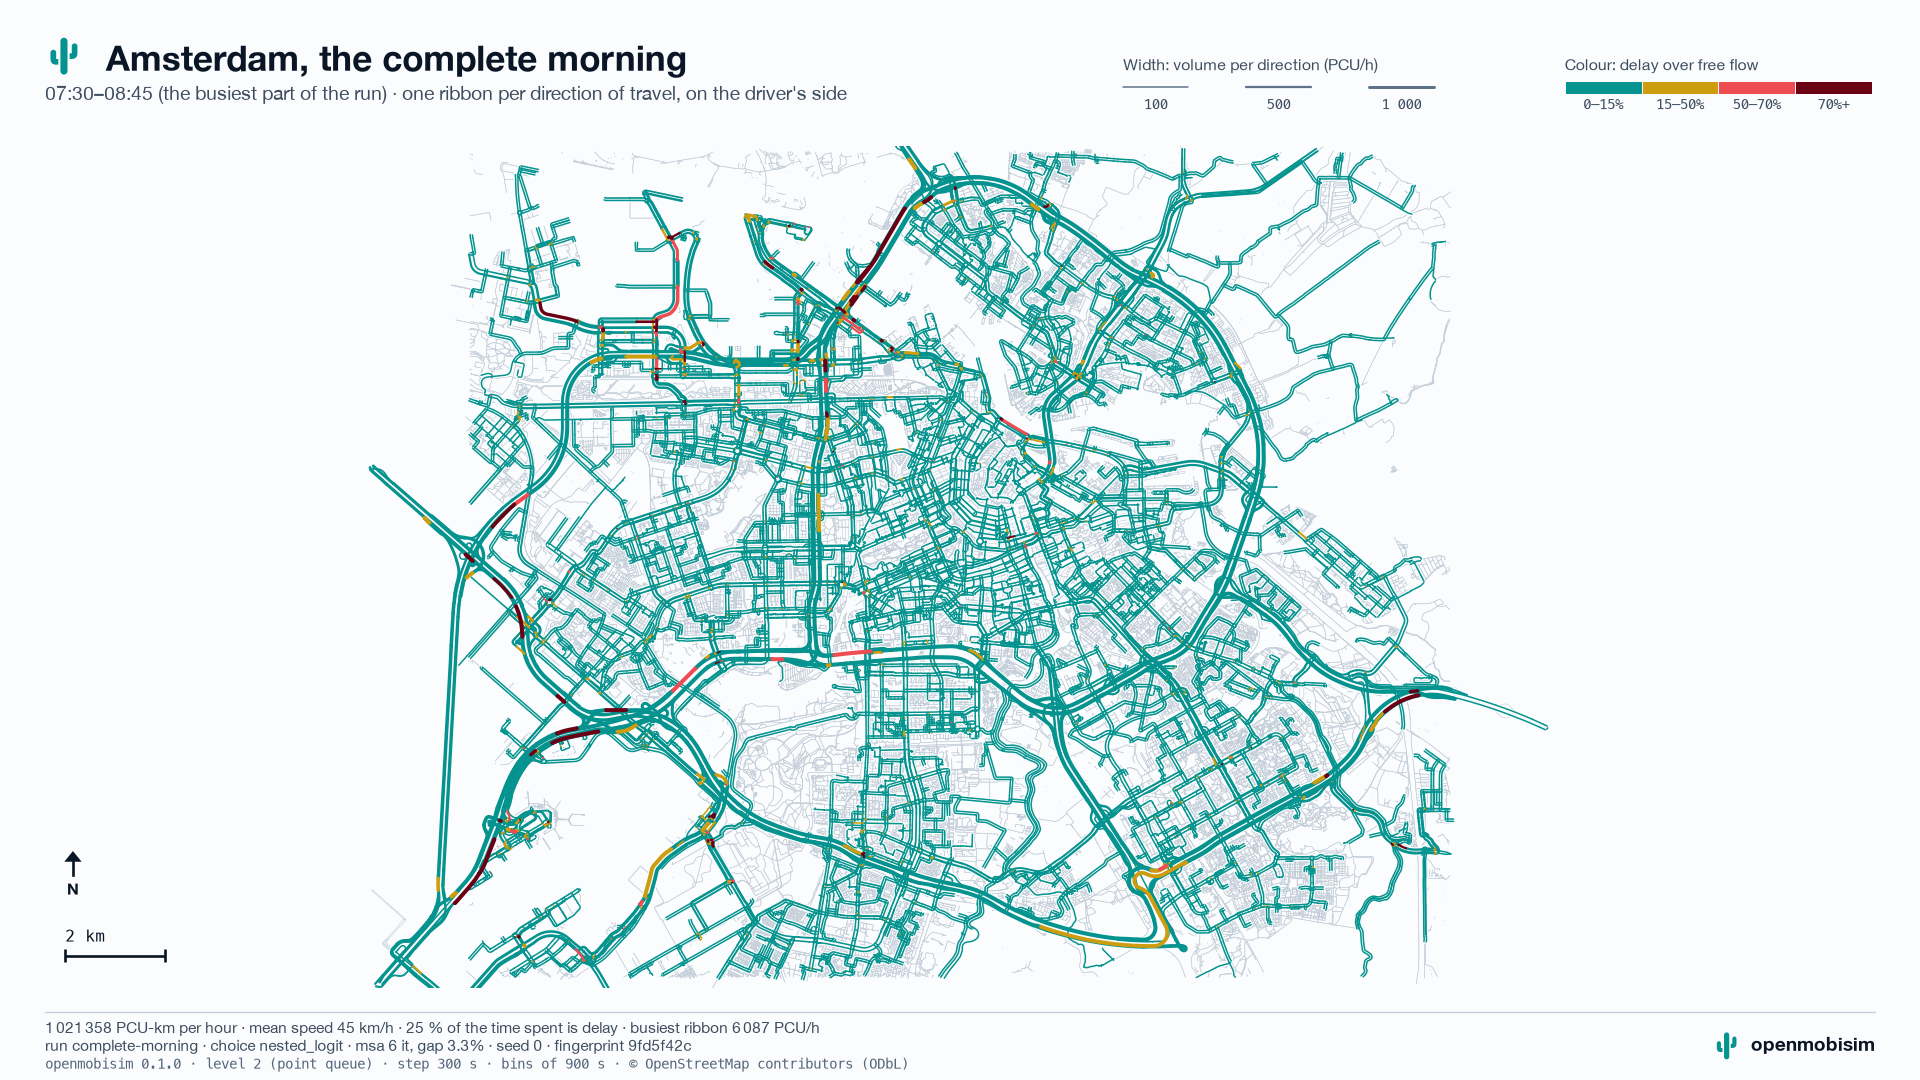

In [16]:
viz.map_link(whole, title="Amsterdam, the complete morning")

In [17]:
viz.map_interactive(whole, "runs/complete-morning/map.html", title="Amsterdam, the complete morning")

**Interactive map:** [runs/complete-morning/map.html](runs/complete-morning/map.html) — file:///private/var/folders/q0/vjghqqvj4dvcq_z2rjmvd0jmw3f5y2/T/tmpjx2flr29/runs/complete-morning/map.html

PosixPath('runs/complete-morning/map.html')

Every speed, coefficient, factor and share above is an uncalibrated default or an illustration; notebook 06 shows how
to change them, and each study's own data — counts, surveys, the fleet — is what turns a minimal study into a real one.

**That was the last tutorial.** Next: your own notebook, from the skeleton at the end of [00 · overview](00_getting_started.ipynb). The documentation: [openmobisim.github.io](https://openmobisim.github.io). Something wrong or unclear? [Report it](https://github.com/bahmanmdd/openmobisim/issues).